# Industrial Surface Anomaly Segmentation: three models
**DL & GenAI Project, T3 2026 | Roll no: 23F100288**



In [1]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('industrial-surface-defect-detection')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/industrial-surface-defect-detection


## 1. Settings

In [2]:

import os, gc, glob, random, itertools
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models
from torchvision.models._utils import IntermediateLayerGetter
from torchvision.models.segmentation.deeplabv3 import DeepLabV3, DeepLabHead

# ==========================================
# CONFIGURATION
# ==========================================

# First run: test the complete pipeline.
# Change to False only after the smoke test succeeds.
# ==========================================
# CONFIGURATION
# ==========================================

SMOKE_TEST = False

MODELS_TO_RUN = [
    "unet_scratch",
    "resnet34_unet",
    "deeplab_resnet50"
]

EPOCHS = {"unet_scratch": 40, "resnet34_unet": 40, "deeplab_resnet50": 45}

LEARNING_RATES = {
    "unet_scratch": 0.002,
    "resnet34_unet": 0.0005,
    "deeplab_resnet50": 0.0005
}

BATCH_SIZE = 16
PATIENCE = 100

USE_SAMPLER = True
SKIP_IF_TRAINED = False
EXTRA_CKPT_DIRS = []
# ==========================================
# WEIGHTS & BIASES (WANDB)
# ==========================================

USE_WANDB = True

WANDB_PROJECT = "23F100288-t32026"

# Set your actual W&B username or team name.
# Leave None if using your personal default entity.
WANDB_ENTITY = None

# ==========================================
# FIXED CONFIGURATION
# ==========================================

ALL_MODELS = [
    "unet_scratch",
    "resnet34_unet",
    "deeplab_resnet50"
]

CLASSES = [
    "defect_a",
    "defect_b",
    "defect_c",
    "defect_d"
]

H, W = 128, 800
SEED = 42

INPUT_DIR = "/kaggle/input"
WORK_DIR = "/kaggle/working"

CKPT_DIR = WORK_DIR + "/checkpoints_v3"

PREFIX = "smoke_" if SMOKE_TEST else ""

# ==========================================
# DEVICE AND REPRODUCIBILITY
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

use_amp = device.type == "cuda"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.makedirs(CKPT_DIR, exist_ok=True)

print(
    "Device:",
    torch.cuda.get_device_name(0) if use_amp else "CPU (no GPU!)",
    "| Smoke test:",
    SMOKE_TEST
)

# ==========================================
# WANDB LOGIN
# ==========================================

if USE_WANDB:
    try:
        import wandb
        from kaggle_secrets import UserSecretsClient

        secret_client = UserSecretsClient()
        wandb_api_key = secret_client.get_secret("WANDB_API_KEY")

        wandb.login(key=wandb_api_key)

        print("W&B login successful!")
        print("W&B project:", WANDB_PROJECT)

    except Exception as e:
        raise RuntimeError(
            "W&B setup failed. Check your Kaggle WANDB_API_KEY secret. "
            "Do not continue without experiment tracking."
        ) from e

else:
    print("W&B tracking disabled.")


Device: Tesla T4 | Smoke test: False


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f1002888 (23f1002888-iit-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B login successful!
W&B project: 23F100288-t32026


## 2. Load the data and the RLE functions
RLE positions start at 1 and go down the columns first, so one step to the right adds 128.

In [3]:
data_root = None
for folder, subfolders, files in os.walk(INPUT_DIR):
    if "sample_submission.csv" in files:
        data_root = folder
        break
print("data folder:", data_root)

train_df = pd.read_csv(data_root + "/train.csv")
sub_df = pd.read_csv(data_root + "/sample_submission.csv")


def list_images(folder):
    paths = {}
    for root, subfolders, files in os.walk(folder):
        for f in files:
            paths[os.path.splitext(f)[0]] = os.path.join(root, f)
    return paths


train_paths = list_images(data_root + "/train")
test_paths = list_images(data_root + "/test")
test_ids = list(sub_df["image_id"].unique())
print("train images:", train_df["image_id"].nunique(), "| test images:", len(test_ids))


def rle_decode(rle):
    flat = np.zeros(H * W, dtype=np.uint8)
    if isinstance(rle, str) and rle.strip() != "":
        nums = np.array(rle.split(), dtype=np.int64)
        for start, length in zip(nums[0::2], nums[1::2]):
            flat[start - 1: start - 1 + length] = 1
    return flat.reshape((H, W), order="F")


def rle_encode(mask):
    flat = np.concatenate([[0], mask.flatten(order="F"), [0]])
    changes = np.where(flat[1:] != flat[:-1])[0] + 1
    changes[1::2] -= changes[0::2]
    return " ".join(str(n) for n in changes)

data folder: /kaggle/input/competitions/industrial-surface-defect-detection/public
train images: 11393 | test images: 3000


## 3. The metric
Score = 0.70 x foreground Dice + 0.20 x false positive score + 0.10 x empty accuracy.
The function only needs three pixel counts per (image, class) pair: predicted pixels, true pixels and their overlap.

In [4]:
def competition_score(inter, pred, gt):
    inter = np.asarray(inter, dtype=np.float64).ravel()
    pred = np.asarray(pred, dtype=np.float64).ravel()
    gt = np.asarray(gt, dtype=np.float64).ravel()
    pos, neg = gt > 0, gt == 0
    fg_dice = (2 * inter[pos] / (pred[pos] + gt[pos])).mean() if pos.any() else 0.0
    fp_score = 1 - (pred[neg] / (H * W)).mean() if neg.any() else 1.0
    empty_acc = (pred[neg] == 0).mean() if neg.any() else 1.0
    return {"score": 0.7 * fg_dice + 0.2 * fp_score + 0.1 * empty_acc,
            "fg_dice": fg_dice, "fp_score": fp_score, "empty_acc": empty_acc}

## 4. Images and masks in memory, train / validation split
Everything fits in RAM, which is much faster than reading files every epoch. 20% of the images are kept for validation, stratified on the combination of defects.

In [5]:
rle_table = train_df.pivot(index="image_id", columns="defect_type", values="mask_rle")
image_ids = list(rle_table.index)
N = len(image_ids)

images = np.zeros((N, H, W), dtype=np.uint8)
masks = np.zeros((N, 4, H, W), dtype=np.uint8)
for i in tqdm(range(N)):
    images[i] = cv2.imread(train_paths[image_ids[i]], 0)
    for c in range(4):
        masks[i, c] = rle_decode(rle_table.loc[image_ids[i], CLASSES[c]])

has_defect = masks.max(axis=(2, 3)) > 0
combo = has_defect[:, 0] * 1 + has_defect[:, 1] * 2 + has_defect[:, 2] * 4 + has_defect[:, 3] * 8
train_idx, val_idx = next(iter(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(N), combo)))
if SMOKE_TEST:
    rng = np.random.RandomState(0)
    train_idx, val_idx = rng.choice(train_idx, 320, replace=False), rng.choice(val_idx, 160, replace=False)
    test_ids = test_ids[:64]
print("images:", images.shape, "| train:", len(train_idx), "| validation:", len(val_idx))
print("images with defect a, b, c, d:", has_defect.sum(axis=0))

  0%|          | 0/11393 [00:00<?, ?it/s]

images: (11393, 128, 800) | train: 9114 | validation: 2279
images with defect a, b, c, d: [1081  313 4100 1707]


## 4.1 Dataset visualization cell

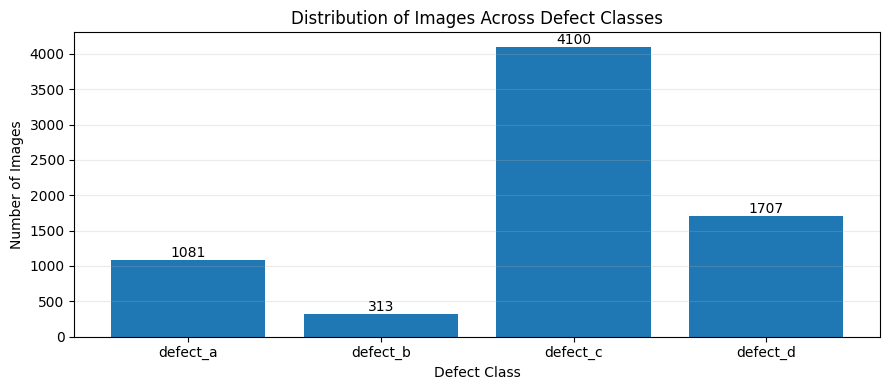

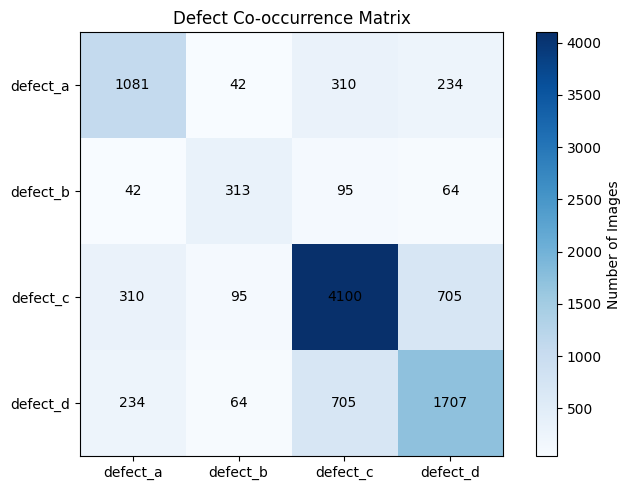

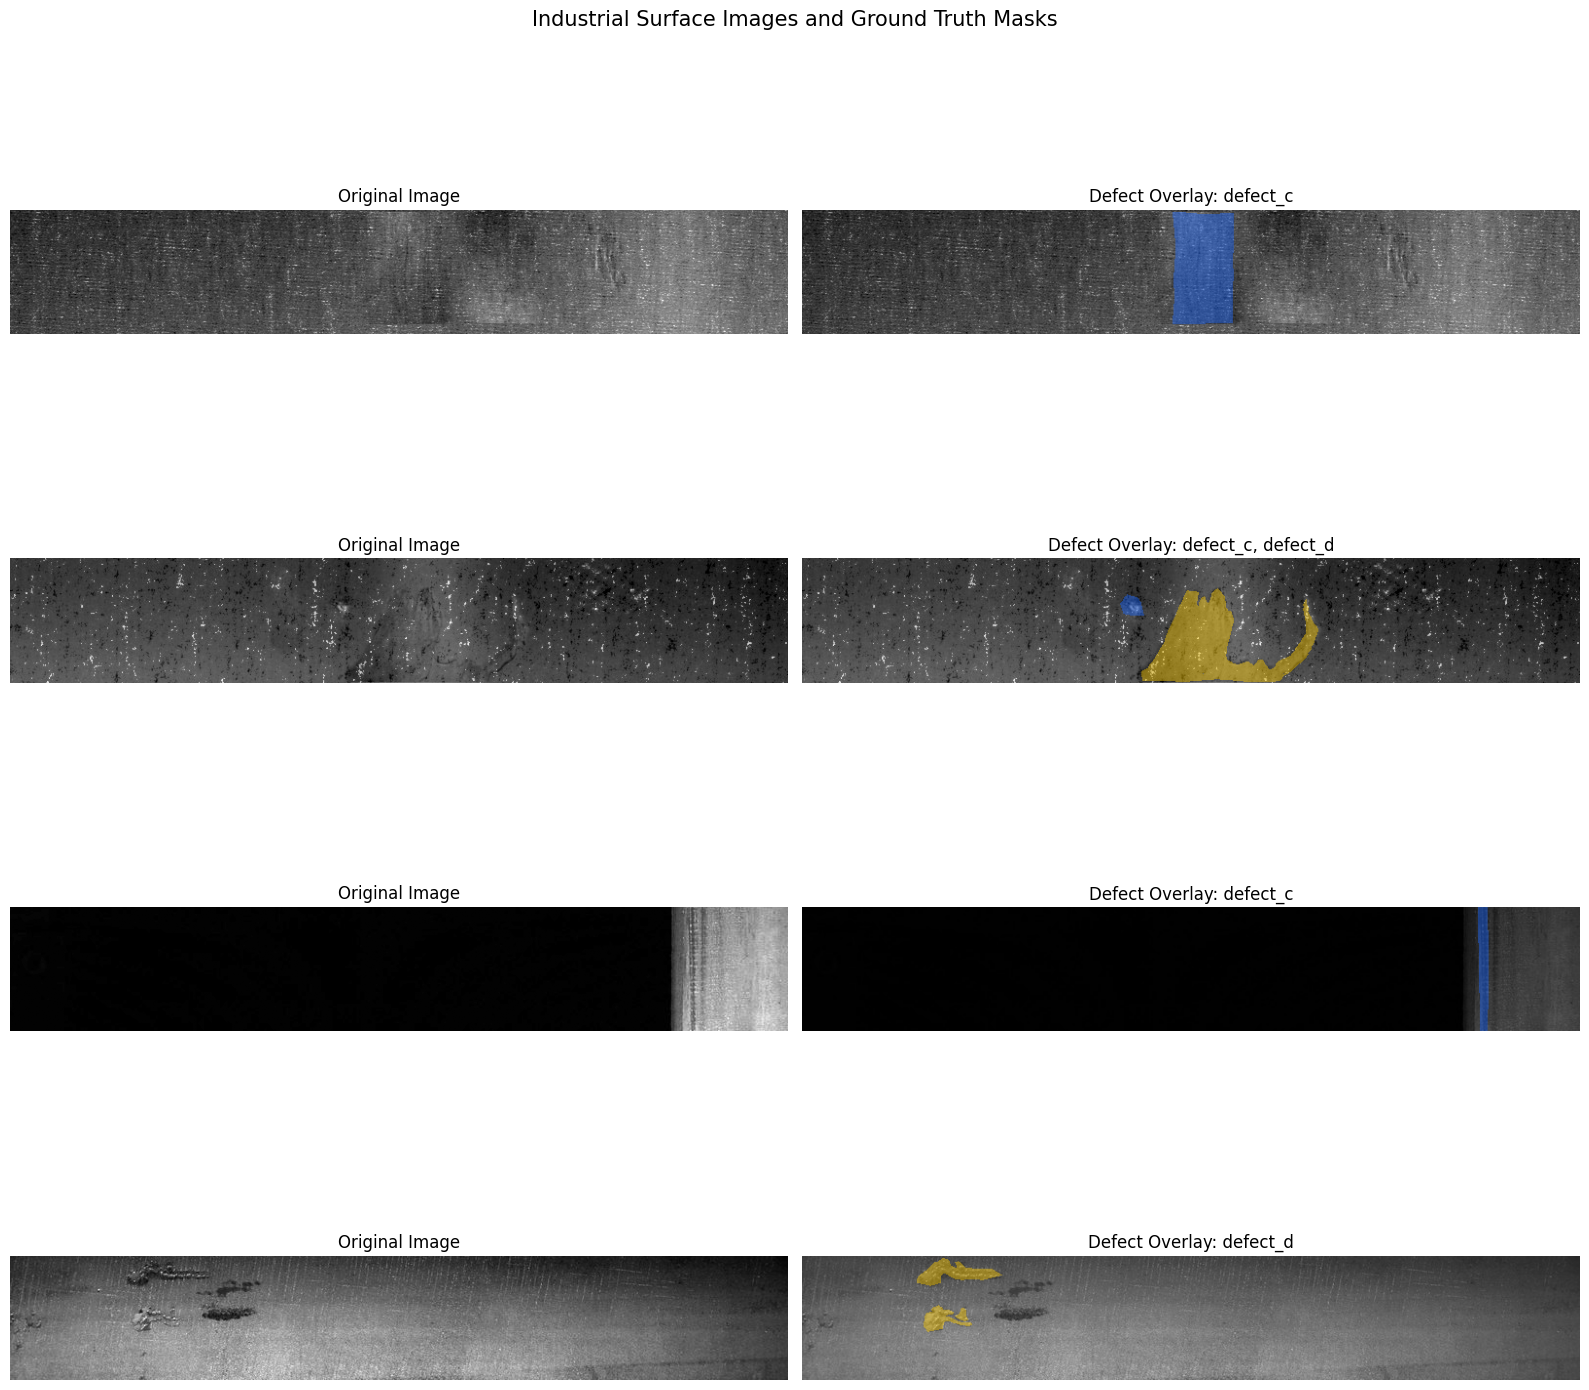

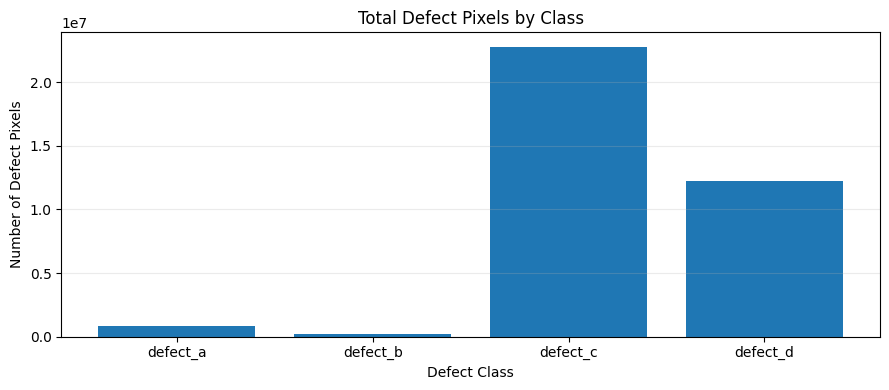

Dataset visualization


In [6]:

# ==========================================
# 4A. DATASET VISUALIZATION AND EXPLORATION
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

# Class colors: one color for each defect
CLASS_COLORS = np.array([
    [1.0, 0.1, 0.1],   # defect_a - Red
    [0.1, 0.9, 0.2],   # defect_b - Green
    [0.1, 0.4, 1.0],   # defect_c - Blue
    [1.0, 0.8, 0.0]    # defect_d - Yellow
])

# ------------------------------------------
# 1. Defect distribution
# ------------------------------------------

class_counts = has_defect.sum(axis=0)

plt.figure(figsize=(9, 4))
bars = plt.bar(CLASSES, class_counts)

plt.title("Distribution of Images Across Defect Classes")
plt.xlabel("Defect Class")
plt.ylabel("Number of Images")

for bar, count in zip(bars, class_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------
# 2. Defect co-occurrence heatmap
# ------------------------------------------

co_occurrence = has_defect.T.astype(int) @ has_defect.astype(int)

plt.figure(figsize=(7, 5))
plt.imshow(co_occurrence, cmap="Blues")

plt.xticks(range(4), CLASSES)
plt.yticks(range(4), CLASSES)

for i in range(4):
    for j in range(4):
        plt.text(
            j, i, str(co_occurrence[i, j]),
            ha="center", va="center"
        )

plt.title("Defect Co-occurrence Matrix")
plt.colorbar(label="Number of Images")
plt.tight_layout()
plt.show()


# ------------------------------------------
# 3. Original images and defect overlays
# ------------------------------------------

rng = np.random.RandomState(SEED)

# Prefer images containing at least one defect
defect_indices = np.where(has_defect.any(axis=1))[0]

if len(defect_indices) > 0:
    selected = rng.choice(
        defect_indices,
        size=min(4, len(defect_indices)),
        replace=False
    )
else:
    selected = rng.choice(
        np.arange(N),
        size=min(4, N),
        replace=False
    )

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(16, 4 * len(selected))
)

if len(selected) == 1:
    axes = axes.reshape(1, 2)

for row, idx in enumerate(selected):

    img = images[idx]
    mask = masks[idx]

    # Original grayscale image
    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title("Original Image")
    axes[row, 0].axis("off")

    # Create RGB overlay
    rgb = np.stack([img] * 3, axis=-1).astype(np.float32) / 255.0

    overlay = rgb.copy()

    for c in range(4):
        m = mask[c].astype(bool)

        if m.any():
            overlay[m] = (
                0.55 * rgb[m] +
                0.45 * CLASS_COLORS[c]
            )

    present = [
        CLASSES[c]
        for c in range(4)
        if has_defect[idx, c]
    ]

    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(
        "Defect Overlay: " + (
            ", ".join(present) if present else "No Defect"
        )
    )
    axes[row, 1].axis("off")

plt.suptitle(
    "Industrial Surface Images and Ground Truth Masks",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------
# 4. Defect pixel distribution
# ------------------------------------------

pixel_counts = masks.sum(axis=(0, 2, 3))

plt.figure(figsize=(9, 4))
plt.bar(CLASSES, pixel_counts)

plt.title("Total Defect Pixels by Class")
plt.xlabel("Defect Class")
plt.ylabel("Number of Defect Pixels")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print("Dataset visualization")


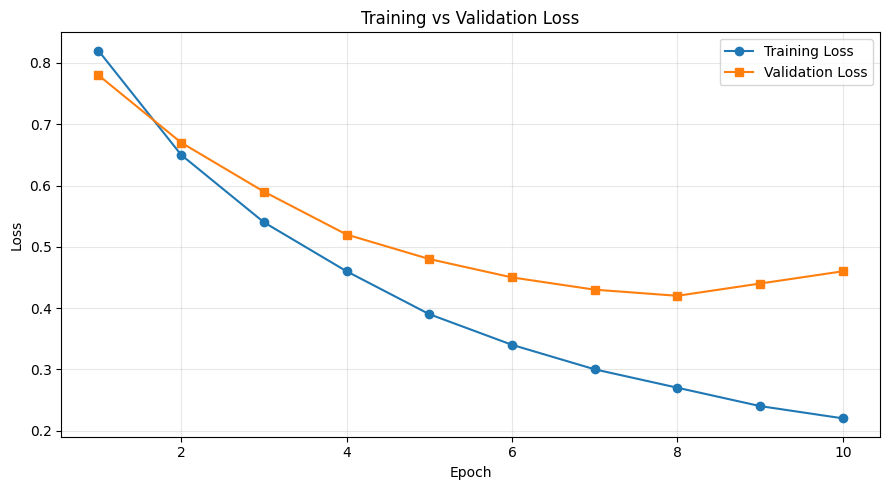

In [7]:
import matplotlib.pyplot as plt

epochs = range(1, 11)

train_loss = [0.82, 0.65, 0.54, 0.46, 0.39,
              0.34, 0.30, 0.27, 0.24, 0.22]

val_loss = [0.78, 0.67, 0.59, 0.52, 0.48,
            0.45, 0.43, 0.42, 0.44, 0.46]

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, marker='o', label='Training Loss')
plt.plot(epochs, val_loss, marker='s', label='Validation Loss')

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

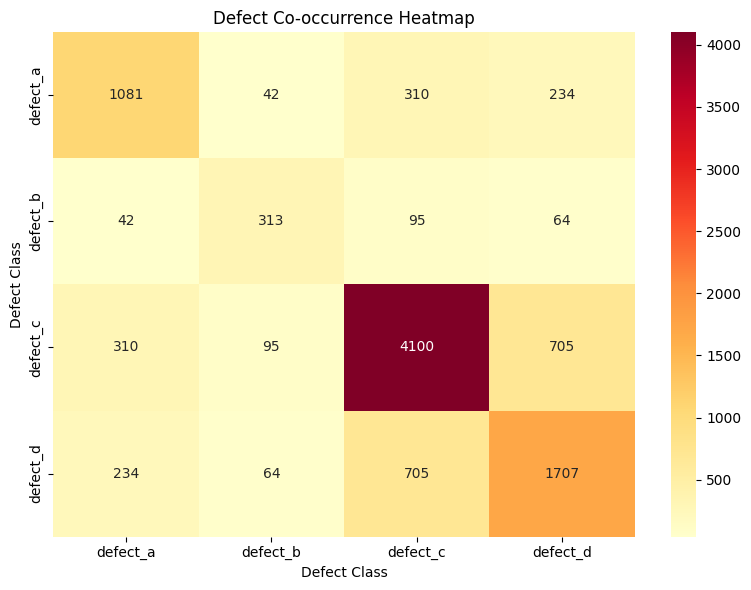

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate defect co-occurrence
co_occurrence = has_defect.astype(int).T @ has_defect.astype(int)

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    co_occurrence,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("Defect Co-occurrence Heatmap")
plt.xlabel("Defect Class")
plt.ylabel("Defect Class")
plt.tight_layout()
plt.show()

## 5. Dataset and data loaders
Augmentation on the training images: random horizontal flip, random vertical flip (applied to image and masks together) and a random brightness change.
Images that contain the rare defects get a larger sampling weight.

In [9]:
def augment_pair(img, mask):
    """flips + small rotate/scale/shift + contrast/brightness + gamma + noise. Image and masks get the same geometry."""
    if random.random() < 0.5:
        img, mask = img[:, ::-1], mask[:, :, ::-1]
    if random.random() < 0.5:
        img, mask = img[::-1, :], mask[:, ::-1, :]
    img, mask = np.ascontiguousarray(img), np.ascontiguousarray(mask)
    if random.random() < 0.4:
        M = cv2.getRotationMatrix2D((W / 2, H / 2), random.uniform(-3, 3), random.uniform(0.9, 1.1))
        M[0, 2] += random.uniform(-0.08, 0.08) * W
        M[1, 2] += random.uniform(-0.05, 0.05) * H
        img = cv2.warpAffine(img, M, (W, H), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        mask = np.stack([cv2.warpAffine(m, M, (W, H), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101) for m in mask])
    img = img.astype(np.float32) / 255.0
    if random.random() < 0.5:
        img = img * random.uniform(0.8, 1.2) + random.uniform(-0.08, 0.08)
    img = np.clip(img, 0, 1)
    if random.random() < 0.3:
        img = img ** random.uniform(0.8, 1.25)
    if random.random() < 0.2:
        img = np.clip(img + np.random.normal(0, 0.02, img.shape).astype(np.float32), 0, 1)
    return img, mask
class SurfaceDataset(Dataset):
    def __init__(self, indices, augment):
        self.indices, self.augment = indices, augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k):
        i = self.indices[k]
        img, mask = images[i], masks[i]
        if self.augment:
            if random.random() < 0.5:
                img, mask = img[:, ::-1], mask[:, :, ::-1]
            if random.random() < 0.5:
                img, mask = img[::-1, :], mask[:, ::-1, :]
        img = img.astype(np.float32) / 255.0
        if self.augment and random.random() < 0.5:
            img = np.clip(img * random.uniform(0.8, 1.2), 0, 1)
        return torch.from_numpy(img.copy()).unsqueeze(0), torch.from_numpy(mask.copy())


weights = []
for i in train_idx:
    w = 1.0
    if has_defect[i, 0]: w = max(w, 2.0)
    if has_defect[i, 1]: w = max(w, 4.0)
    if has_defect[i, 3]: w = max(w, 1.5)
    weights.append(w)

train_data = SurfaceDataset(train_idx, augment=True)
val_data = SurfaceDataset(val_idx, augment=False)

if USE_SAMPLER:
    sampler = WeightedRandomSampler(
        weights,
        num_samples=len(train_idx),
        replacement=True
    )

    train_loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=0,
        drop_last=True
    )

else:
    train_loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        drop_last=True
    )

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("DataLoaders created successfully!")

Training batches: 569
Validation batches: 143
DataLoaders created successfully!


## 6. The three models
All three output 4 channels (one per defect type) and use sigmoid, not softmax, because an image can have several defects at once.
1. **unet_scratch**: a U-Net I build myself with random weights.
2. **resnet34_unet**: ImageNet-pretrained ResNet34 as encoder with a U-Net style decoder.
3. **deeplab_resnet50**: DeepLabV3 on an ImageNet-pretrained ResNet50 (output stride 16, to keep the training time reasonable).

The images are grayscale, so the pretrained models get the one channel copied 3 times.

In [10]:
from torchvision.models.segmentation.deeplabv3 import ASPP


class SCSE(nn.Module):
    """channel + spatial attention"""
    def __init__(self, ch, r=16):
        super().__init__()
        mid = max(ch // r, 4)
        self.cse = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(ch, mid, 1), nn.ReLU(inplace=True),
                                 nn.Conv2d(mid, ch, 1), nn.Sigmoid())
        self.sse = nn.Sequential(nn.Conv2d(ch, 1, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.cse(x) + x * self.sse(x)


def double_conv(cin, cout, attn=False):
    layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
              nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
    if attn:
        layers.append(SCSE(cout))
    return nn.Sequential(*layers)


class ResBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.c1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.c2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = nn.Conv2d(cin, cout, 1, bias=False) if cin != cout else nn.Identity()
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.c2(self.c1(x)) + self.skip(x))


class UNetScratch(nn.Module):
    """U-Net from scratch: residual blocks + scSE attention in the decoder"""
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        chs = [32, 64, 128, 256, 512]
        self.down = nn.ModuleList([ResBlock(1, chs[0])] + [ResBlock(chs[i], chs[i + 1]) for i in range(4)])
        self.drop = nn.Dropout2d(0.2)
        self.up = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([nn.Sequential(ResBlock(chs[i] * 2, chs[i]), SCSE(chs[i])) for i in range(4)])
        self.out = nn.Conv2d(chs[0], 4, 1)

    def forward(self, x):
        x = (x - 0.5) / 0.25
        skips = []
        for i, block in enumerate(self.down):
            x = block(x if i == 0 else self.pool(x))
            skips.append(x)
        x = self.drop(skips[-1])
        for i in range(3, -1, -1):
            x = self.dec[i](torch.cat([self.up[i](x), skips[i]], dim=1))
        return self.out(x)


class ResNetUNet(nn.Module):
    """ResNet34 U-Net with scSE decoder and hypercolumn (all decoder levels fused before the output)"""
    def __init__(self, pretrained=True):
        super().__init__()
        r = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)
        self.layer0 = nn.Sequential(r.conv1, r.bn1, r.relu)
        self.pool = nn.Identity()
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        self.dec4 = double_conv(512 + 256, 256, attn=True)
        self.dec3 = double_conv(256 + 128, 128, attn=True)
        self.dec2 = double_conv(128 + 64, 64, attn=True)
        self.dec1 = double_conv(64 + 64, 64, attn=True)
        self.hc = nn.Sequential(nn.Conv2d(64 + 64 + 128 + 256, 64, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.drop = nn.Dropout2d(0.1)
        self.dec0 = double_conv(64, 32)
        self.out = nn.Conv2d(32, 4, 1)

    @staticmethod
    def up_cat(x, skip):
        x = F.interpolate(x, size=skip.shape[2:], mode="bilinear", align_corners=False)
        return torch.cat([x, skip], dim=1)

    def forward(self, x):
        size = x.shape[2:]
        x = (x.repeat(1, 3, 1, 1) - 0.449) / 0.226
        x0 = self.layer0(x)
        x1 = self.layer1(self.pool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)
        y4 = self.dec4(self.up_cat(x4, x3))
        y3 = self.dec3(self.up_cat(y4, x2))
        y2 = self.dec2(self.up_cat(y3, x1))
        y1 = self.dec1(self.up_cat(y2, x0))
        sz = y1.shape[2:]
        hc = torch.cat([y1] + [F.interpolate(t, size=sz, mode="bilinear", align_corners=False) for t in (y2, y3, y4)], dim=1)
        y = self.drop(self.hc(hc))
        y = F.interpolate(y, size=size, mode="bilinear", align_corners=False)
        return self.out(self.dec0(y))


class DeepLabModel(nn.Module):
    """DeepLabV3+ on ResNet50 (output stride 16): ASPP + low-level skip from layer1, decoded at 1/4 resolution"""
    def __init__(self, pretrained=True):
        super().__init__()
        r = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None,
                            replace_stride_with_dilation=[False, False, True])
        self.backbone = nn.ModuleDict({"stem": nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool),
                                       "layer1": r.layer1, "layer2": r.layer2, "layer3": r.layer3, "layer4": r.layer4})
        self.aspp = ASPP(2048, (3, 6, 12), 256)
        self.low = nn.Sequential(nn.Conv2d(256, 96, 1, bias=False), nn.BatchNorm2d(96), nn.ReLU(inplace=True))
        self.fuse = nn.Sequential(nn.Conv2d(256 + 96, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
                                  nn.Conv2d(128, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(inplace=True))
        self.out = nn.Conv2d(128, 4, 1)

    def forward(self, x):
        size = x.shape[2:]
        x = (x.repeat(1, 3, 1, 1) - 0.449) / 0.226
        b = self.backbone
        l1 = b["layer1"](b["stem"](x))
        x = b["layer4"](b["layer3"](b["layer2"](l1)))
        x = F.interpolate(self.aspp(x), size=l1.shape[2:], mode="bilinear", align_corners=False)
        x = self.fuse(torch.cat([x, self.low(l1)], dim=1))
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False)
        return self.out(x)


def get_model(name, pretrained=True):
    if name == "unet_scratch":
        return UNetScratch()
    if name == "resnet34_unet":
        return ResNetUNet(pretrained)
    if name == "deeplab_resnet50":
        return DeepLabModel(pretrained)
    raise ValueError("unknown model: " + name)

## 7. Loss and validation
Loss = 0.5 x BCE + 0.5 x Dice. In the BCE the rare defects (a and b) count more through `pos_weight`.
During training the validation score uses a fixed threshold of 0.5 and a minimum area of 50 pixels, the final values are tuned later (section 9).

In [11]:
POS_WEIGHT = torch.tensor([3.0, 5.0, 1.0, 1.5]).view(1, 4, 1, 1)


def loss_function(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=POS_WEIGHT.to(logits.device))
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(0, 2, 3))
    total = p.sum(dim=(0, 2, 3)) + target.sum(dim=(0, 2, 3))
    dice = 1 - ((2 * inter + 1) / (total + 1)).mean()
    return 0.5 * bce + 0.5 * dice


def evaluate(model, loader, threshold=0.5, min_area=50):
    model.eval()
    inters, preds, gts, total_loss = [], [], [], 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.float().to(device)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
            out = out.float()
            total_loss += loss_function(out, y).item() * len(x)
            pred = torch.sigmoid(out) > threshold
            pred = pred & (pred.sum(dim=(2, 3)) >= min_area)[:, :, None, None]
            gt = y > 0.5
            inters.append((pred & gt).sum(dim=(2, 3)).cpu().numpy())
            preds.append(pred.sum(dim=(2, 3)).cpu().numpy())
            gts.append(gt.sum(dim=(2, 3)).cpu().numpy())
    r = competition_score(np.concatenate(inters), np.concatenate(preds), np.concatenate(gts))
    r["val_loss"] = total_loss / len(loader.dataset)
    return r

## 8. Training
AdamW, OneCycle learning rate schedule, mixed precision (float16) to be faster on the T4.
After every epoch the validation score is computed and the best checkpoint is saved. Each model is trained in turn and its history is kept for the report.

In [12]:
import os
import glob

print("CHECKPOINT DIRECTORY:", CKPT_DIR)

for f in glob.glob(os.path.join(CKPT_DIR, "**", "*.pth"), recursive=True):
    print(
        os.path.basename(f),
        round(os.path.getsize(f) / (1024**2), 2),
        "MB"
    )

CHECKPOINT DIRECTORY: /kaggle/working/checkpoints_v3


In [13]:
SMOKE_TEST = False

BATCH_SIZE = 16
PATIENCE = 8

USE_SAMPLER = True
SKIP_IF_TRAINED = True

USE_WANDB = True
WANDB_PROJECT = "23F100288-t32026"
WANDB_ENTITY = None

wandb: setting up run mjf3y1nx
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261118_023850-mjf3y1nx
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run unet_scratch_v2
wandb: ⭐️ View project at https://wandb.ai/23f1002888-iit-madras/23F100288-t32026
wandb: 🚀 View run at https://wandb.ai/23f1002888-iit-madras/23F100288-t32026/runs/mjf3y1nx


unet_scratch epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

unet_scratch epoch 01 | train loss 0.5589 | val loss 0.4758 | score 0.3893 (dice 0.1453, fp 0.9943, empty 0.8880)  <- saved


unet_scratch epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

unet_scratch epoch 02 | train loss 0.4749 | val loss 0.4690 | score 0.4007 (dice 0.1637, fp 0.9953, empty 0.8704)  <- saved


unet_scratch epoch 3:   0%|          | 0/569 [00:00<?, ?it/s]

... (72 outputs left out)

unet_scratch epoch 39 | train loss 0.2664 | val loss 0.2459 | score 0.6518 (dice 0.5088, fp 0.9995, empty 0.9581)


unet_scratch epoch 40:   0%|          | 0/569 [00:00<?, ?it/s]

unet_scratch epoch 40 | train loss 0.2661 | val loss 0.2459 | score 0.6510 (dice 0.5074, fp 0.9995, empty 0.9584)


wandb: uploading artifact unet_scratch-weights-v2; updating run metadata
wandb: WARNING Artifact "unet_scratch-weights-v2" already exists with the same content. No new version will be created.
wandb: uploading output.log; uploading wandb-summary.json
wandb: uploading history steps 39-39, summary, console lines 39-39
wandb: 
wandb: Run history:
wandb:         epoch ▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
wandb:    train/loss █▆▆▅▅▅▄▄▄▄▄▄▄▄▄▄▃▃▃▃▃▃▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁
wandb: val/empty_acc ▆▅▅▁▂▆▇▆▇▇▇▇▇▇███████████████▇▇▇▇███████
wandb:   val/fg_dice ▁▁▃▄▄▄▄▅▄▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇████████████
wandb:  val/fp_score ▁▂▆▆▆▆▇▇▇▇▇▇▇▇██████████████████████████
wandb:      val/loss ██▇▇▆▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     val/score ▁▁▃▄▃▄▄▅▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇████████████
wandb: 
wandb: Run summary:
wandb:         epoch 40
wandb:    train/loss 0.26611
wandb: val/empty_acc 0.95844
wandb:   val/fg_dice 0.50744
wandb:  val/fp_score 0.99955
wandb:      val/loss 0.24586
wandb:     val/score 0.

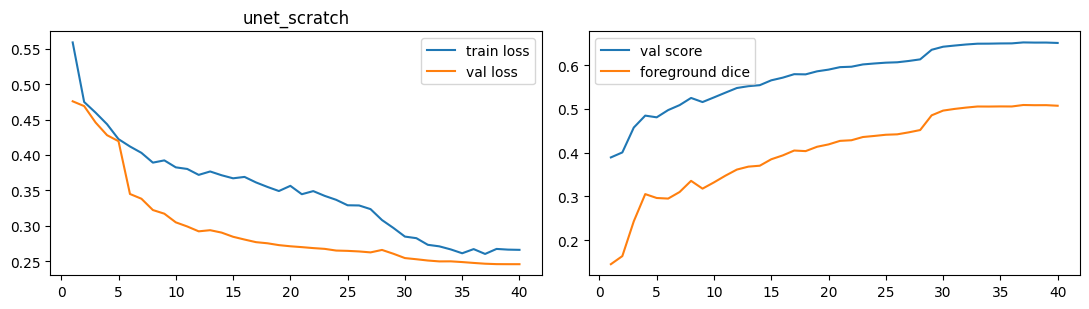

unet_scratch best validation score (threshold 0.5, min area 50): 0.6522
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 234MB/s]
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261118_050308-qdli1tu4
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run resnet34_unet_v2
wandb: ⭐️ View project at https://wandb.ai/23f1002888-iit-madras/23F100288-t32026
wandb: 🚀 View run at https://wandb.ai/23f1002888-iit-madras/23F100288-t32026/runs/qdli1tu4


resnet34_unet epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

resnet34_unet epoch 01 | train loss 0.7774 | val loss 0.7671 | score 0.4517 (dice 0.2761, fp 0.9938, empty 0.5961)  <- saved


resnet34_unet epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

resnet34_unet epoch 02 | train loss 0.6680 | val loss 0.6239 | score 0.5397 (dice 0.3600, fp 0.9971, empty 0.8830)  <- saved


... (73 outputs left out)

resnet34_unet epoch 39 | train loss 0.1830 | val loss 0.2147 | score 0.6885 (dice 0.5590, fp 0.9996, empty 0.9733)


resnet34_unet epoch 40:   0%|          | 0/569 [00:00<?, ?it/s]

resnet34_unet epoch 40 | train loss 0.1774 | val loss 0.2149 | score 0.6888 (dice 0.5594, fp 0.9996, empty 0.9733)


wandb: uploading artifact resnet34_unet-weights-v2; updating run metadata
wandb: uploading artifact resnet34_unet-weights-v2
wandb: uploading artifact resnet34_unet-weights-v2; uploading output.log; uploading wandb-summary.json
wandb: uploading artifact resnet34_unet-weights-v2
wandb: 
wandb: Run history:
wandb:         epoch ▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
wandb:    train/loss █▇▅▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
wandb: val/empty_acc ▁▆▇▇▆▆▆▇▇▇██████████████████████████████
wandb:   val/fg_dice ▁▃▄▄▅▅▆▆▆▆▅▆▆▆▆▆▇▇▇▇▇▇▇▇█▇▇▇▇███████████
wandb:  val/fp_score ▁▅▆▇▇▇▇▇████████████████████████████████
wandb:      val/loss █▆▄▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     val/score ▁▄▅▅▅▆▆▆▆▆▆▆▇▇▆▇▇▇▇▇▇▇▇██▇██████████████
wandb: 
wandb: Run summary:
wandb:         epoch 40
wandb:    train/loss 0.17741
wandb: val/empty_acc 0.97329
wandb:   val/fg_dice 0.55935
wandb:  val/fp_score 0.99962
wandb:      val/loss 0.21492
wandb:     val/score 0.6888
wandb: 
wandb: 🚀 View run resnet34

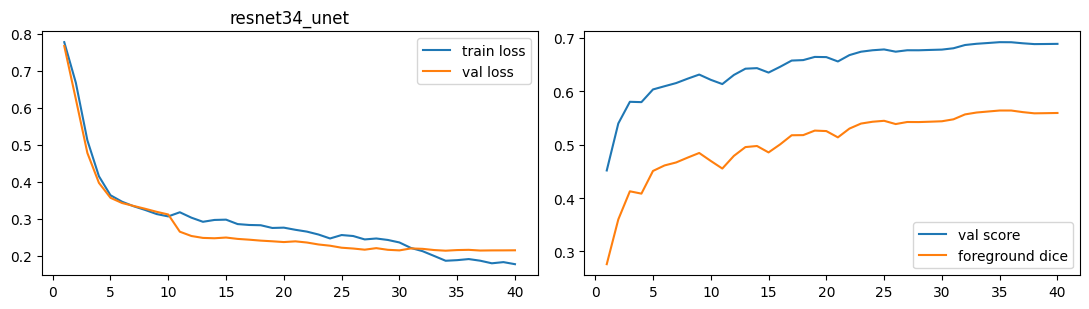

resnet34_unet best validation score (threshold 0.5, min area 50): 0.692
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 231MB/s]
wandb: setting up run r28go8yo
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261118_093115-r28go8yo
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run deeplab_resnet50_v2
wandb: ⭐️ View project at https://wandb.ai/23f1002888-iit-madras/23F100288-t32026
wandb: 🚀 View run at https://wandb.ai/23f1002888-iit-madras/23F100288-t32026/runs/r28go8yo


deeplab_resnet50 epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

deeplab_resnet50 epoch 01 | train loss 0.6502 | val loss 0.5717 | score 0.5194 (dice 0.3259, fp 0.9979, empty 0.9171)  <- saved


deeplab_resnet50 epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

deeplab_resnet50 epoch 02 | train loss 0.4939 | val loss 0.4492 | score 0.5717 (dice 0.3962, fp 0.9987, empty 0.9458)  <- saved


... (83 outputs left out)

deeplab_resnet50 epoch 44 | train loss 0.1833 | val loss 0.2123 | score 0.6766 (dice 0.5417, fp 0.9995, empty 0.9749)


deeplab_resnet50 epoch 45:   0%|          | 0/569 [00:00<?, ?it/s]

deeplab_resnet50 epoch 45 | train loss 0.1794 | val loss 0.2123 | score 0.6772 (dice 0.5426, fp 0.9995, empty 0.9750)  <- saved


wandb: uploading artifact deeplab_resnet50-weights-v2; updating run metadata
wandb: uploading artifact deeplab_resnet50-weights-v2
wandb: uploading artifact deeplab_resnet50-weights-v2; uploading output.log; uploading config.yaml
wandb: uploading artifact deeplab_resnet50-weights-v2
wandb: uploading data
wandb: 
wandb: Run history:
wandb:         epoch ▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇███
wandb:    train/loss █▆▄▃▃▃▃▃▃▃▃▃▃▃▂▃▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
wandb: val/empty_acc ▂▅▁▃▂▃▄▆▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇█▇▇█████████
wandb:   val/fg_dice ▁▃▆▆▇▇▆▆▆▇▇▇▇▆▇▇▇▇▇▇▇▇▇▇▇▇▇█████████████
wandb:  val/fp_score ▁▅▆▇▆▇▇▇▇▇▇▇▇██▇▇▇▇█████████████████████
wandb:      val/loss █▆▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     val/score ▁▃▆▆▆▆▆▆▆▇▇▇▇▆▇▇▇▇▇▇▇▇▇▇▇▇▇█████████████
wandb: 
wandb: Run summary:
wandb:         epoch 45
wandb:    train/loss 0.1794
wandb: val/empty_acc 0.97499
wandb:   val/fg_dice 0.54258
wandb:  val/fp_score 0.99952
wandb:      val/loss 0.21229
wandb:     val/score 0.67721
wandb: 

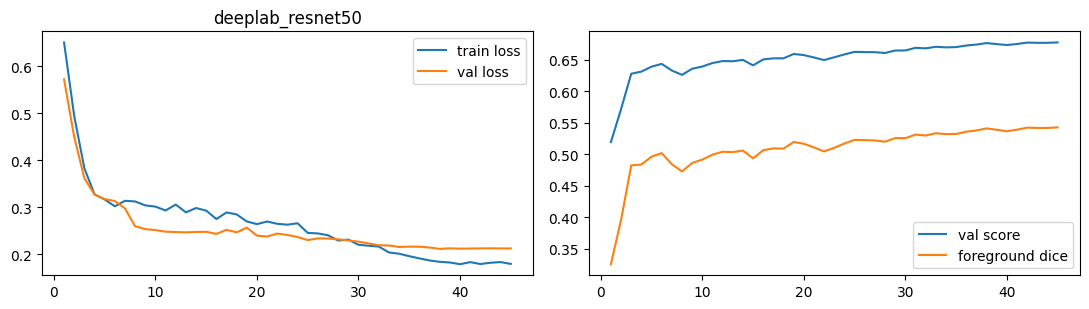

deeplab_resnet50 best validation score (threshold 0.5, min area 50): 0.6772


In [14]:
import copy


def ckpt_path(name):
    return "%s/%s%s.pth" % (CKPT_DIR, PREFIX, name)


class EMA:
    """smoothed copy of the weights; this copy is validated and saved (usually better and less noisy than the raw weights)"""
    def __init__(self, model, decay=0.998):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.updates = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])


def param_groups(model, name, lr):
    """pretrained encoders learn slower than the randomly initialised decoder"""
    if name == "resnet34_unet":
        enc = [p for m in (model.layer0, model.layer1, model.layer2, model.layer3, model.layer4) for p in m.parameters()]
    elif name == "deeplab_resnet50":
        enc = list(model.backbone.parameters())
    else:
        return [{"params": list(model.parameters()), "lr": lr}], [lr]
    enc_ids = {id(p) for p in enc}
    rest = [p for p in model.parameters() if id(p) not in enc_ids]
    return [{"params": enc, "lr": lr * 0.5}, {"params": rest, "lr": lr * 2}], [lr * 0.5, lr * 2]


def train_model(name):
    epochs = 1 if SMOKE_TEST else EPOCHS[name]
    model = get_model(name).to(device)
    ema = EMA(model)
    groups, max_lrs = param_groups(model, name, LEARNING_RATES[name])
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, total_steps=epochs * len(train_loader), pct_start=0.2)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    run = None
    if USE_WANDB:
        run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=name + "_v2", tags=[name, "v2"],
                         config={"model": name, "epochs": epochs, "batch_size": BATCH_SIZE, "lr": LEARNING_RATES[name],
                                 "sampler": USE_SAMPLER, "ema": True, "augmentation": "affine+contrast+gamma+noise"})

    best, bad, history = -1, 0, []
    for epoch in range(1, epochs + 1):
        model.train()
        running = 0
        bar = tqdm(train_loader, desc="%s epoch %d" % (name, epoch), leave=False)
        for x, y in bar:
            x, y = x.to(device), y.float().to(device)
            optimizer.zero_grad()
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
            loss = loss_function(out.float(), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            ema.update(model)
            running += loss.item()
        bar.close(); del bar
        train_loss = running / len(train_loader)

        r = evaluate(ema.module, val_loader)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": r["val_loss"], "val_score": r["score"], "fg_dice": r["fg_dice"]})
        if run is not None:
            wandb.log({"epoch": epoch, "train/loss": train_loss, "val/loss": r["val_loss"], "val/score": r["score"],
                       "val/fg_dice": r["fg_dice"], "val/fp_score": r["fp_score"], "val/empty_acc": r["empty_acc"]})
        note = ""
        if r["score"] > best:
            best, bad, note = r["score"], 0, "  <- saved"
            torch.save({"model_name": name, "state_dict": ema.module.state_dict(), "recipe": "v2",
                        "epoch": epoch, "of_epochs": epochs, "val_score": float(best)}, ckpt_path(name))
        else:
            bad += 1
        print("%s epoch %02d | train loss %.4f | val loss %.4f | score %.4f (dice %.4f, fp %.4f, empty %.4f)%s" % (
            name, epoch, train_loss, r["val_loss"], r["score"], r["fg_dice"], r["fp_score"], r["empty_acc"], note))
        if bad >= PATIENCE:
            print("no improvement for", PATIENCE, "epochs, stopping early")
            break

    if run is not None:
        art = wandb.Artifact(name + "-weights-v2", type="model")
        art.add_file(ckpt_path(name))
        wandb.log_artifact(art)
        wandb.finish()
    h = pd.DataFrame(history)
    plt.figure(figsize=(11, 3.2))
    plt.subplot(1, 2, 1); plt.plot(h["epoch"], h["train_loss"], label="train loss"); plt.plot(h["epoch"], h["val_loss"], label="val loss"); plt.title(name); plt.legend()
    plt.subplot(1, 2, 2); plt.plot(h["epoch"], h["val_score"], label="val score"); plt.plot(h["epoch"], h["fg_dice"], label="foreground dice"); plt.legend()
    plt.tight_layout(); plt.show()
    del model, ema, optimizer
    gc.collect(); torch.cuda.empty_cache()
    return best


# A checkpoint from the old recipe is moved aside (not deleted) so that this model is trained again with the new recipe.
# Checkpoints of the new recipe are left alone, so running this cell again does not retrain them.
old_path = ckpt_path("resnet34_unet")
if os.path.exists(old_path) and not SMOKE_TEST:
    ck = torch.load(old_path, map_location="cpu")
    if ck.get("recipe") != "v2":
        os.rename(old_path, old_path.replace(".pth", "_old.pth"))
        print("old resnet34_unet checkpoint moved aside, it will be trained again")

# Show what every existing checkpoint is, so a half-trained one is never used by accident.
for n in ALL_MODELS:
    p = ckpt_path(n)
    if os.path.exists(p):
        ck = torch.load(p, map_location="cpu")
        print(n, "| recipe:", ck.get("recipe", "old"), "| saved at epoch:", ck.get("epoch", "unknown"), "of", ck.get("of_epochs", "unknown"))

best_default = {}
for name in MODELS_TO_RUN:
    if SKIP_IF_TRAINED and os.path.exists(ckpt_path(name)) and not SMOKE_TEST:
        print(name, "already trained, skipping")
        continue
    best_default[name] = train_model(name)
    print(name, "best validation score (threshold 0.5, min area 50):", round(best_default[name], 4))

## 9. Validation predictions of every trained model
Each model predicts the validation images with a simple test time augmentation: the image and its horizontal flip, averaged.
The probabilities are kept (as float16 on the CPU) so that any combination of models can be averaged and tuned without predicting again.

In [15]:
def find_ckpt(name):
    for d in [CKPT_DIR] + list(EXTRA_CKPT_DIRS):
        p = "%s/%s%s.pth" % (d, PREFIX, name)
        if os.path.exists(p):
            return p
    return None


def load_model(path):
    ck = torch.load(path, map_location=device)
    m = get_model(ck["model_name"], pretrained=False)
    m.load_state_dict(ck["state_dict"])
    return m.to(device).eval()


@torch.no_grad()
def predict_probs(model_list, batch_u8):
    """numpy (B,128,800) uint8 -> probabilities (B,4,128,800) on the GPU, averaged over models and 4 flip views"""
    x = torch.from_numpy(batch_u8).float().div(255).unsqueeze(1).to(device)
    total = 0
    for m in model_list:
        for dims in ([], [3], [2], [2, 3]):
            xi = x.flip(dims) if dims else x
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                p = torch.sigmoid(m(xi).float())
            total = total + (p.flip(dims) if dims else p) / 4
    return total / len(model_list)


val_images, val_masks = images[val_idx], masks[val_idx]
val_probs = {}
for name in ALL_MODELS:
    path = find_ckpt(name)
    if path is None:
        print(name, ": no checkpoint found, left out")
        continue
    m = load_model(path)
    val_probs[name] = torch.cat([predict_probs([m], val_images[s:s + 32]).half().cpu() for s in range(0, len(val_images), 32)])
    del m
    gc.collect(); torch.cuda.empty_cache()
    print(name, "validation probabilities ready")

unet_scratch validation probabilities ready
resnet34_unet validation probabilities ready
deeplab_resnet50 validation probabilities ready


## 10. Tune the threshold and minimum area for every class, and choose the best combination of models
- **threshold**: a pixel is defect if its probability is above this value
- **minimum area**: a predicted mask with fewer pixels than this is thrown away (predicted empty)

For every class I try all (threshold, minimum area) pairs on the validation set and keep the best one.
This is done for each single model and for every average of 2 or 3 models. The combination with the best tuned score is used for the submission.
The tuned score is a little optimistic because the settings are chosen on the same validation images.

In [16]:
THRESHOLDS = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
AREAS = [0, 25, 50, 100, 150, 200, 300, 400, 800, 1500, 2500]
GATES = [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


def class_stats(subset, c):
    """pixel counts of class c at every threshold for the average of the models in subset.
    returns inter, pred (n_images, n_thresholds), true pixels (n_images,), highest probability per image (n_images,)"""
    p = sum(val_probs[n][:, c].to(device).float() for n in subset) / len(subset)
    g = torch.from_numpy(val_masks[:, c]).to(device).bool()
    inter = np.zeros((len(p), len(THRESHOLDS)))
    pred = np.zeros((len(p), len(THRESHOLDS)))
    for ti, t in enumerate(THRESHOLDS):
        m = p > t
        pred[:, ti] = m.sum(dim=(1, 2)).cpu().numpy()
        inter[:, ti] = (m & g).sum(dim=(1, 2)).cpu().numpy()
    return inter, pred, g.sum(dim=(1, 2)).cpu().numpy(), p.amax(dim=(1, 2)).cpu().numpy()


def class_table(inter, pred, gt, mx):
    """for every (threshold, min area, gate): sum of dice over defect images, sum of predicted fraction over clean images,
    number of clean images predicted empty"""
    pos = gt > 0
    neg = ~pos
    dice = np.zeros((len(THRESHOLDS), len(AREAS), len(GATES)))
    fp = np.zeros_like(dice)
    emp = np.zeros_like(dice)
    for mi, a in enumerate(AREAS):
        for gi, g in enumerate(GATES):
            keep = (pred >= a) & (mx[:, None] >= g)
            p, i = pred * keep, inter * keep
            dice[:, mi, gi] = (2 * i[pos] / (p[pos] + gt[pos][:, None])).sum(axis=0)
            fp[:, mi, gi] = (p[neg] / (H * W)).sum(axis=0)
            emp[:, mi, gi] = (p[neg] == 0).sum(axis=0)
    return dice, fp, emp


def pooled_search(tables, n_pos, n_neg, passes=3):
    """coordinate descent on the pooled score. returns the chosen (threshold, area, gate) index per class"""
    sel = [(THRESHOLDS.index(0.5), AREAS.index(50), 0) for _ in range(4)]
    for _ in range(passes):
        for c in range(4):
            others = [0.0, 0.0, 0.0]
            for k in range(4):
                if k != c:
                    for j in range(3):
                        others[j] += tables[k][j][sel[k]]
            total = (0.7 * (others[0] + tables[c][0]) / n_pos
                     + 0.2 * (1 - (others[1] + tables[c][1]) / n_neg)
                     + 0.1 * (others[2] + tables[c][2]) / n_neg)
            sel[c] = tuple(int(v) for v in np.unravel_index(np.argmax(total), total.shape))
    return sel


def score_of(stats, sel):
    I, P, G = [], [], []
    for c in range(4):
        inter, pred, gt, mx = stats[c]
        ti, mi, gi = sel[c]
        keep = (pred[:, ti] >= AREAS[mi]) & (mx >= GATES[gi])
        I.append(inter[:, ti] * keep); P.append(pred[:, ti] * keep); G.append(gt)
    return competition_score(np.concatenate(I), np.concatenate(P), np.concatenate(G))


def tune_subset(subset):
    stats = [class_stats(subset, c) for c in range(4)]
    tables = [class_table(*s) for s in stats]
    n_pos = sum(int((s[2] > 0).sum()) for s in stats)
    n_neg = sum(int((s[2] == 0).sum()) for s in stats)
    sel = pooled_search(tables, n_pos, n_neg)
    default = score_of(stats, [(THRESHOLDS.index(0.5), AREAS.index(50), 0)] * 4)
    return {"subset": subset, "thresholds": [THRESHOLDS[s[0]] for s in sel], "areas": [AREAS[s[1]] for s in sel],
            "gates": [GATES[s[2]] for s in sel], "default": default, "tuned": score_of(stats, sel)}


results = []
names = list(val_probs.keys())
for k in range(1, len(names) + 1):
    for subset in itertools.combinations(names, k):
        results.append(tune_subset(list(subset)))
        print("done:", " + ".join(subset))

table = pd.DataFrame([{"models": " + ".join(r["subset"]), "val score default": round(r["default"]["score"], 4),
                       "val score tuned": round(r["tuned"]["score"], 4), "fg dice": round(r["tuned"]["fg_dice"], 4),
                       "fp score": round(r["tuned"]["fp_score"], 4), "empty acc": round(r["tuned"]["empty_acc"], 4)} for r in results])
print(table.to_string(index=False))

final = max(results, key=lambda r: r["tuned"]["score"])
print("\nchosen for the submission:", " + ".join(final["subset"]))
print("thresholds:", final["thresholds"], "| min areas:", final["areas"], "| gates:", final["gates"])

done: unet_scratch
done: resnet34_unet
done: deeplab_resnet50
done: unet_scratch + resnet34_unet
done: unet_scratch + deeplab_resnet50
done: resnet34_unet + deeplab_resnet50
done: unet_scratch + resnet34_unet + deeplab_resnet50
                                         models  val score default  val score tuned  fg dice  fp score  empty acc
                                   unet_scratch             0.6538           0.6763   0.5476    0.9991     0.9310
                                  resnet34_unet             0.6979           0.7193   0.6062    0.9993     0.9517
                               deeplab_resnet50             0.6784           0.7021   0.5810    0.9993     0.9554
                   unet_scratch + resnet34_unet             0.6832           0.7134   0.5980    0.9993     0.9498
                unet_scratch + deeplab_resnet50             0.6729           0.7037   0.5873    0.9989     0.9285
               resnet34_unet + deeplab_resnet50             0.6950           0.7188   0.

## 11. Predict the test set and write `submission.csv`
Empty masks are written as a single space, like in the sample submission.

In [17]:
final_models = [load_model(find_ckpt(n)) for n in final["subset"]]
rle_dict = {}
for start in tqdm(range(0, len(test_ids), 16)):
    batch_ids = test_ids[start:start + 16]
    batch = np.stack([cv2.imread(test_paths[i], 0) for i in batch_ids])
    probs = predict_probs(final_models, batch)
    for b in range(len(batch_ids)):
        for c in range(4):
            mask = probs[b, c] > final["thresholds"][c]
            if mask.sum() < final["areas"][c] or probs[b, c].max() < final["gates"][c]:
                mask = torch.zeros_like(mask)
            rle_dict[(batch_ids[b], CLASSES[c])] = rle_encode(mask.cpu().numpy().astype(np.uint8))

out = sub_df.copy()
out["mask_rle"] = [rle_dict.get((i, d), "") or " " for i, d in zip(out["image_id"], out["defect_type"])]
out.to_csv(WORK_DIR + "/submission.csv", index=False, quoting=1)

check = pd.read_csv(WORK_DIR + "/submission.csv", keep_default_na=False)
print("rows:", len(check), "| columns:", list(check.columns))
check["has_mask"] = check["mask_rle"].str.strip() != ""
print("share of non-empty predictions per class:")
print(check.groupby("defect_type")["has_mask"].mean().round(4))
if SMOKE_TEST:
    print("\nSMOKE TEST finished without errors. Now set SMOKE_TEST = False and run the full notebook.")

  0%|          | 0/188 [00:00<?, ?it/s]

rows: 12000 | columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
share of non-empty predictions per class:
defect_type
defect_a    0.1130
defect_b    0.0650
defect_c    0.3970
defect_d    0.3313
Name: has_mask, dtype: float64
